# Intro
The objective of this study is to create a classification model to classify   12-lead ECG records of 10 seconds length between this classes:

|Records	|Superclass	|Description|
|----------|:-------------:|------:|
|9517	 |  NORM | Normal ECG |
|5473	 |  MI	 |  Myocardial  Infarction |
| 5237 |	STTC |	ST/T Change |
| 4901 |	CD   |	Conduction Disturbance |
| 2649 |	HYP  |	Hypertrophy |


> [!NOTE] Multi-class classification
> Note that this a record can belong to more than one class. For example, a record can be classified as MI and CD at the same time. 

# Dataset

[Dataset](https://physionet.org/content/ptb-xl/1.0.2/)
1. Standard set of 12 leads (I, II, III, AVL, AVR, AVF, V1, ..., V6) with reference electrodes on the right arm.
2. For most records also the heart’s axis (heart_axis) and infarction stadium (infarction_stadium1 and infarction_stadium2, if present) were extracted.
4. A large fraction of the records was validated by a second cardiologist.
5. All records were validated by a technical expert focusing mainly on signal characteristics.(Should be low noise and good signal quality)
ECGs and patients are identified by unique identifiers (ecg_id and patient_id).

1. Identifiers: Each record is identified by a unique ecg_id. The corresponding patient is encoded via patient_id.

2. General Metadata: demographic and recording metadata such as age, sex, height, weight, nurse, site, device and recording_date

3. ECG statements: core components are scp_codes (SCP-ECG statements as a dictionary with entries of the form statement: likelihood, where likelihood is set to 0 if unknown) and report (report string). Additional fields are heart_axis, infarction_stadium1, infarction_stadium2, validated_by, second_opinion, initial_autogenerated_report and validated_by_human.

4. Signal Metadata: signal quality such as noise (static_noise and burst_noise), baseline drifts (baseline_drift) and other artifacts such as electrodes_problems. We also provide extra_beats for counting extra systoles and pacemaker for signal patterns indicating an active pacemaker.

5. Cross-validation Folds: Folds 1-8 as training set, fold 9 as validation set and fold 10 as test set.

# Metadata
First thing we will do is explore the metadata of the dataset, with emphasis on reported superclasses, as they will be our target classes.

In [17]:
import os
import pandas as pd
import numpy as np
import wfdb
import ast
from tqdm import tqdm
path = '../../data/ptbl/'
# load and convert annotation data
Y = pd.read_csv(path+'ptbxl_database.csv', index_col='ecg_id')
Y.scp_codes = Y.scp_codes.apply(lambda x: ast.literal_eval(x))
# Load scp_statements.csv for diagnostic aggregation
agg_df = pd.read_csv(path+'scp_statements.csv', index_col=0)
agg_df = agg_df[agg_df.diagnostic == 1]


def aggregate_diagnostic(y_dic):
    tmp = []
    for key in y_dic.keys():
        if key in agg_df.index:
            tmp.append(agg_df.loc[key].diagnostic_class)
    return list(set(tmp))


# Apply diagnostic superclass
Y['diagnostic_superclass'] = Y.scp_codes.apply(aggregate_diagnostic)

In [18]:
Y.describe(include='all')

,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr,diagnostic_superclass
count,21799.000000,21799.000000,21799.000000,6974.000000,9421.000000,20326.000000,21782.000000,21799,21799,21799,...,1598,3260,613,30,1949,291,21799.000000,21799,21799,21799
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11,21795,9887,...,317,124,103,14,128,4,NaN,21799,21799,27
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CS100 3,1992-02-06 11:47:42,sinus rhythm. normal ecg.,...,", V6",", I-AVR,",alles,V6,1ES,"ja, pacemaker",NaN,records100/00000/00001_lr,records500/00000/00001_hr,[NORM]
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6140,2,1734,...,221,953,140,8,405,285,NaN,1,1,9069
mean,11250.156521,62.769301,0.479150,166.702323,70.995223,2.291745,1.544945,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,5.503005,NaN,NaN,NaN
std,6235.026404,32.308813,0.499577,10.867321,15.878803,3.254033,4.172883,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2.874948,NaN,NaN,NaN
min,302.000000,2.000000,0.000000,6.000000,5.000000,0.000000,0.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN
25%,5974.500000,50.000000,0.000000,160.000000,60.000000,0.000000,0.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,NaN,NaN
50%,11419.000000,62.000000,0.000000,166.000000,70.000000,1.000000,1.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,6.000000,NaN,NaN,NaN
75%,16607.500000,72.000000,1.000000,174.000000,80.000000,3.000000,2.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,8.000000,NaN,NaN,NaN


## Target Classes

Check to see the distribution of the target classes and see how much overlap there is

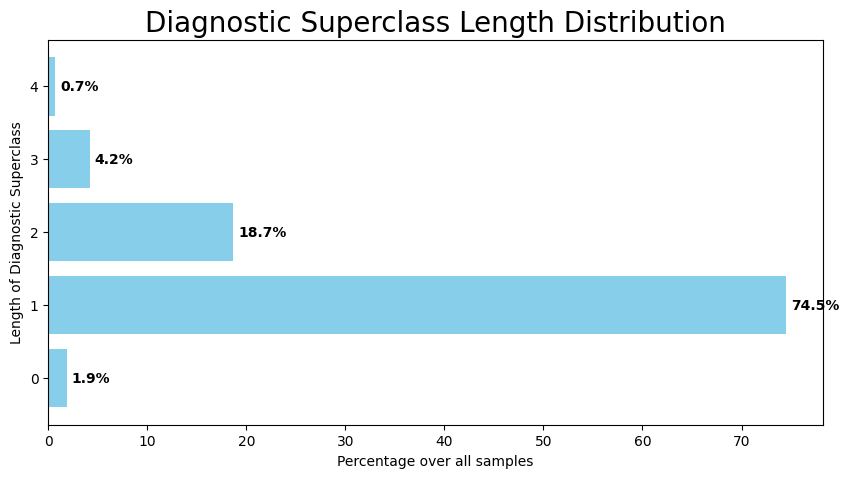

Number of empty diagnostics:  411
Number of multiple diagnostics:  5144


In [19]:
import matplotlib.pyplot as plt
# Calculate the length of each diagnostic superclass
lengths = Y['diagnostic_superclass'].apply(len)

# Calculate the value counts for each length
vc = lengths.value_counts().sort_index()

# Calculate the percentage
percentages = vc.values / vc.values.sum() * 100

# Create the plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(vc.index, percentages, color='skyblue')
# Add title and labels
ax.set_title("Diagnostic Superclass Length Distribution", fontsize=20)
ax.set_xlabel("Percentage over all samples")
ax.set_ylabel("Length of Diagnostic Superclass")

# Add percentage labels next to the bars
for i in range(len(percentages)):
    ax.text(percentages[i] + 0.5, vc.index[i], f"{percentages[i]:.1f}%", va='center', ha='left', fontweight='bold')

# Display the plot
plt.show()
# Check index of the diagnostics that dont have any superclass
empty_diagnotics_index = ([index for index in Y.index if len(Y['diagnostic_superclass'].loc[index]) == 0])
# Check for the ones with 2 or more superclasses
multiple_diagnotics_index = ([index for index in Y.index if len(Y['diagnostic_superclass'].loc[index]) >= 2])
print('Number of empty diagnostics: ', len(empty_diagnotics_index))
print('Number of multiple diagnostics: ', len(multiple_diagnotics_index))


There are some records that dont have a superclass, we will remove them from the dataset
In addition, we we can see that there are some records that have multiple superclasses, therefore we cant use a softmax activation function in the output layer of our model. Each class is independent of the others.

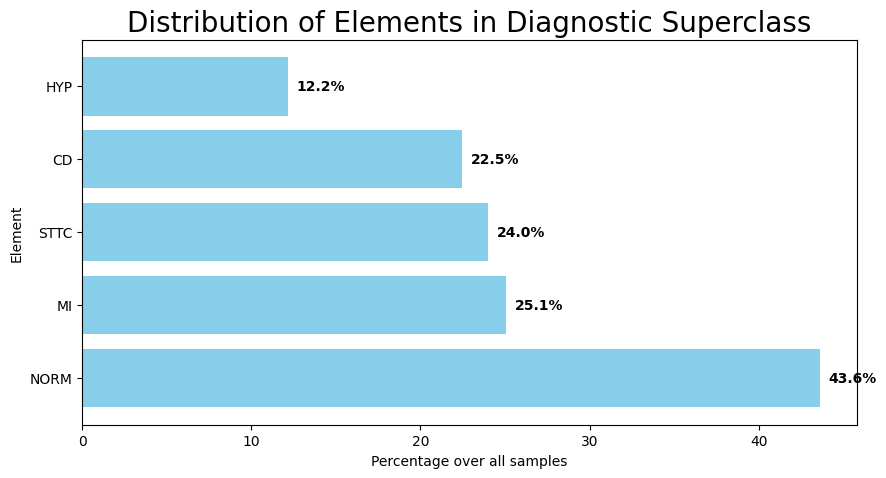

In [20]:
flat_list = [item for sublist in Y['diagnostic_superclass'] for item in sublist]
# total number of samples in the dataset 
total_samples = len(Y)
# Convert to a pandas Series and calculate value counts
element_counts = pd.Series(flat_list).value_counts()

# Calculate the percentage
percentages = element_counts.values / total_samples * 100


# Create the plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(element_counts.index, percentages, color='skyblue')

# Add title and labels
ax.set_title("Distribution of Elements in Diagnostic Superclass", fontsize=20)
ax.set_xlabel("Percentage over all samples")
ax.set_ylabel("Element")

# Add percentage labels next to the bars
for i in range(len(percentages)):
    ax.text(percentages[i] + 0.5, element_counts.index[i], f"{percentages[i]:.1f}%", va='center', ha='left', fontweight='bold')

# Display the plot
plt.show()

We can see the that the classes are imbalanced, with the NORM class being the most balanced, and the HYP class being the least balanced. We will need to take this into account when training our model. Given that we can have multiple classes per record data augmentation will be difficult, therefore we should consider using loss weights to account for the class imbalance.


In [21]:
# We will see for each length of the diagnostic superclass, what is the distribution of elements
import pandas as pd
import matplotlib.pyplot as plt

# Calculate the length of each list
Y['length'] = Y['diagnostic_superclass'].apply(len)

# Initialize a dictionary to hold the counts of each element by list length
element_distribution = {}

# Iterate over each row in the DataFrame
for _, row in Y.iterrows():
    length = row['length']
    elements = row['diagnostic_superclass']
    
    if length not in element_distribution:
        element_distribution[length] = []
    
    element_distribution[length].extend(elements)

# Convert the distribution dictionary to a DataFrame for easier analysis
distribution_df = pd.DataFrame([
    (length, element) for length, elements in element_distribution.items() for element in elements
], columns=['Length', 'Element'])

# Calculate the counts of each element by list length
counts = distribution_df.groupby(['Length', 'Element']).size().unstack(fill_value=0)

# Calculate the percentages
percentages = counts.div(counts.sum(axis=1), axis=0) * 100

percentages

Element,CD,HYP,MI,NORM,STTC
Length,,,,,
1,10.514652,3.293524,15.587294,55.829845,14.774686
2,30.420354,15.560472,25.553097,5.371190,23.094887
3,20.239391,25.063475,25.426188,0.253899,29.017048
4,25.000000,25.000000,25.000000,0.159236,24.840764


We can see that most of the times when the the diagnosis is NORM there are no other classes present, yet it cannot be considered as equivalent to the absence of the other classes, as there are some records that have NORM as a superclass and another superclass as well. Therefore, we will consider the NORM class as a superclass on its own, and not as the absence of the other classes.

### Conclusion
We will have to use a multi-label classification model, with 5 classes, multiple classes can be present in a record, the classes are imbalanced, and we will have to use loss postiive weights to account for this.

## Other Metadata
We will explore if any of the other metadata can be used to improve the model performance